In [1]:
cd ./wrkDir/s19/s19-1

/work/xiangchong.li/work/galSim-HSC/s19/s19-1


In [18]:
%pylab inline
import os
import sys
import numpy as np
import pandas as pd
import scipy.stats as stats
import sim_analysis_utilities as utilities

import matplotlib
import matplotlib.pyplot as plt

import logging
logging.basicConfig(filename='6-ReGaus_selBias.log',level=logging.INFO)

anaDir='./anaCat_newS19Mask/'
pltDir='./plot/selBias-2/'
assert os.path.isdir(anaDir)
if not os.path.isdir(pltDir):
    os.mkdir(pltDir)
inFname=os.path.join(anaDir,'allSim.h5')

Populating the interactive namespace from numpy and matplotlib


# Selection Bias of Resolution Cut
## Preparation

Read data and apply weak lensing. 90 degree rotation is applied for cuts except the resolution cut.

In [19]:
# Read catalog
dataP =   pd.read_hdf(inFname,mode='r')
data=dataP.to_records()

In [20]:
min_snr=10
max_snr=None
max_magA10=25.5
min_res=0.3
max_mag=24.5
max_logb=-0.38
max_sigma_e=0.4
max_e=2.

wlmask2    =   utilities.galaxy_selector(catalog=data,
                min_snr=min_snr, #snr
                max_snr=max_snr,
                max_magA10=max_magA10, #magA10
                min_res=min_res, #res
                max_mag=max_mag, #mag
                max_logb=max_logb,#logb
                force_90_pair=False,
                max_e=max_e,     #absE
                max_sigma_e=max_sigma_e) #sigma_e
dataU2=data[wlmask2]

In [14]:
min_snr=10
max_snr=None
max_magA10=25.5
min_res=0.3
max_mag=24.5
max_logb=-0.38
max_sigma_e=0.4
max_e=2.

wlmask    =   utilities.galaxy_selector(catalog=data,
                min_snr=min_snr, #snr
                max_snr=max_snr,
                max_magA10=max_magA10, #magA10
                min_res=min_res, #res
                max_mag=max_mag, #mag
                max_logb=max_logb,#logb
                force_90_pair=True,
                max_e=max_e,     #absE
                max_sigma_e=max_sigma_e) #sigma_e
dataU=data[wlmask]

In [15]:
weight=utilities.get_weight_model(dataU)*dataU['weight']
weight2=utilities.get_weight_model(dataU2)*dataU2['weight']

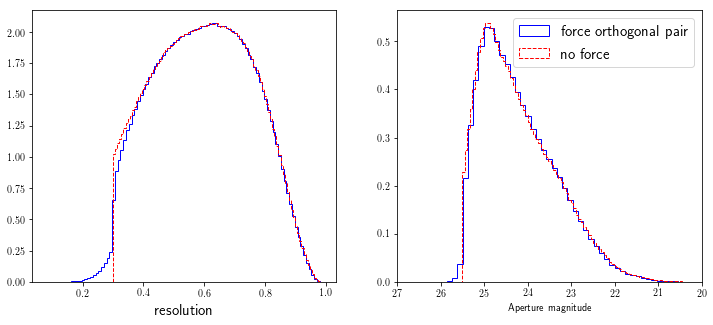

In [23]:
fig = plt.figure(figsize=(12,5))
ax = fig.add_subplot(1,2,1)

ax.hist(dataU['res'],bins=100,weights=weight,density=True,histtype='step',label=r'force orthogonal pair',color='blue')
ax.hist(dataU2['res'],bins=100,weights=weight2,density=True,histtype='step',label='no force',color='red',ls='--')
ax.set_xlabel('resolution',fontsize=15)

ax = fig.add_subplot(1,2,2)
ax.hist(dataU['magA10'],bins=100,weights=weight,density=True,histtype='step',label=r'force orthogonal pair',color='blue')
ax.hist(dataU2['magA10'],bins=100,weights=weight2,density=True,histtype='step',label='no force',color='red',ls='--')
ax.set_xlim(27,20)
ax.set_xlabel('Aperture magnitude')
plt.legend(fontsize=15,loc='upper right')
plt.savefig(os.path.join(pltDir,'selBias_PDF_90rot_no90rot.eps'))

In [33]:
def get_mc_bins(shearBinName,nbin_1d):
    outcomes=np.load(shearBinName)

    nsim   =   len(outcomes)
    psf_e1 =   np.zeros(nsim)
    psf_e2 =   np.zeros(nsim)
    weight =   np.zeros(nsim)
    g1_true=   np.zeros(nsim)
    g2_true=   np.zeros(nsim)
    g1_bins=   np.zeros((nbin_1d,nsim))
    g2_bins=   np.zeros((nbin_1d,nsim))
    sigma_g_bins=   np.zeros((nbin_1d,nsim))

    for iout,outcome in enumerate(outcomes):
        g1_true[iout]  =   outcome[0]
        g2_true[iout]  =   outcome[1]
        g1_bins[:,iout]  =   outcome[2]
        g2_bins[:,iout]  =   outcome[3]
        sigma_g_bins[:,iout]  =   outcome[4]
        psf_e1[iout]  =   outcome[5]
        psf_e2[iout]  =   outcome[6]
        weight[iout]  =   outcome[7]

    m1_bins    =   np.zeros(nbin_1d)
    a1_bins    =   np.zeros(nbin_1d)
    sigm1_bins =   np.zeros(nbin_1d)
    siga1_bins =   np.zeros(nbin_1d)

    # For each of the sliding bins in SNR/resolution.
    for j in range(nbin_1d):
        sigma_vals = sigma_g_bins[j,:]
        division_val = np.sqrt(weight)
        division_val[division_val<1.e-6] = 1.e-6
        sigma_vals /= division_val
        # remove unrealistic sim
        tmp_use = (sigma_vals < 1.e+10)
        # get multiplicative bias and additive bias
        m1_bins[j],a1_bins[j], \
        sigm1_bins[j],siga1_bins[j]= \
            utilities.get_m_c_a(g1_bins[j,tmp_use],
                                g2_bins[j,tmp_use],
                                g1_true[tmp_use],
                                g2_true[tmp_use],
                                psf_e1[tmp_use],
                                psf_e2[tmp_use],
                                sigma_vals[tmp_use],
                                separate_components=False)
    
    return m1_bins,a1_bins,sigm1_bins,siga1_bins

def makePlotSelBias(obsname,subname,dataU,doPlot=False):
    nbin_1d=5
    shape_weight = utilities.get_weight_model(dataU)*dataU['weight']
    p_edges=np.zeros(nbin_1d)

    if obsname=="mag":
        cutplace=r'\rm{mag}=24.5'
        obs=dataU[obsname]
        bin_size  =   0.025
        first_msk=(obs >= 24.5 - bin_size)
    elif obsname=="magA10":
        cutplace=r'\rm{magA}=25.5'
        obs=dataU[obsname]
        bin_size  =   0.025
        first_msk=(obs >= 25.5 - bin_size)
    elif obsname=="res":
        cutplace=r'\rm{res}=0.3'
        obs=dataU[obsname]
        bin_size  =   0.01
        first_msk=(obs <= 0.3 + bin_size)
    elif obsname=="snr":
        cutplace=r'\rm{snr}=10'
        obs=dataU[obsname]
        bin_size  =   1.
        first_msk=(obs <= 10. + bin_size)
        
    if subname=='mizuki_Z':
        xlabel='redshift (mizuki)'
        sub=dataU['mizuki_Z']
        sub_lowers  =   np.array([0.0,0.5,1.0,1.5,2.5])
        sub_uppers  =   np.array([0.5,1.0,1.5,2.5,4.0])
        isub=0
        for lb,ub in zip(sub_lowers,sub_uppers):
            tmp_msk=(sub>=lb)&(sub<ub)
            n_first_bin = np.sum(shape_weight[tmp_msk&first_msk])
            p_edges[isub] = n_first_bin / (np.sum(shape_weight[tmp_msk]) * bin_size)
            isub+=1
        sub_ave=(sub_lowers+sub_uppers)/2.

    print(p_edges)
    shearBinName1=   os.path.join(pltDir,'shear_selbias_%s_mizuki_Z.npy' %obsname)
    shearBinName2=   os.path.join(pltDir,'shear_selbias_%s_mizuki_Z_90rot.npy' %obsname)

    m1,a1,sigm1,siga1=get_mc_bins(shearBinName1,nbin_1d)
    m2,a2,sigm2,siga2=get_mc_bins(shearBinName2,nbin_1d)

    if doPlot:
        fig = plt.figure(figsize=(12,5))
        ax = fig.add_subplot(1,2,1)
        ax.errorbar(sub_ave, m1-m2,sigm1*np.sqrt(2.))
        ax.set_xlabel(xlabel,fontsize=15)
        ax.set_ylabel(r'$m_{\rm{sel}}$',fontsize=15)
        ax.set_title('Multiplicative bias')
        plt.grid()


        ax = fig.add_subplot(1,2,2)
        ax.errorbar(sub_ave, a1-a2,siga1*np.sqrt(2.))
        ax.set_xlabel(xlabel,fontsize=15)
        ax.set_ylabel(r'$a_{\rm{sel}}$',fontsize=15)
        ax.set_title('Additive bias')
        plt.grid()
        plt.tight_layout()
        #plt.savefig(pltDir+'%s_Delta_m_model_2d.png'%(prefix))

        fig = plt.figure(figsize=(12,5))
        ax = fig.add_subplot(1,2,1)
        ax.errorbar(sub_ave, (m1-m2)/p_edges,sigm1*np.sqrt(2.)/p_edges)
        plt.xlabel(xlabel,fontsize=15)
        plt.ylabel(r'$m_{\rm{sel}}/p(%s)$' %cutplace,fontsize=15)
        plt.title('Multiplicative bias of selection')
        plt.grid()


        ax = fig.add_subplot(1,2,2)
        ax.errorbar(sub_ave, (a1-a2)/p_edges,siga1*np.sqrt(2.)/p_edges)
        plt.xlabel(xlabel,fontsize=15)
        plt.ylabel(r'$a_{\rm{sel}}/p(%s)$' %cutplace,fontsize=15)
        plt.title('Additive bias of selection')
        plt.grid()
        plt.tight_layout()
        plt.savefig(os.path.join(pltDir,'selBias_%s.eps' %(obsname)))
    return sub_ave,m1-m2,sigm1*np.sqrt(2.),a1-a2,siga1*np.sqrt(2.), p_edges

/work/xiangchong.li/lsstsw/miniconda/envs/lsst-scipipe/lib/python3.7/site-packages/ipykernel_launcher.py:84: RuntimeWarning: invalid value encountered in greater_equal
/work/xiangchong.li/lsstsw/miniconda/envs/lsst-scipipe/lib/python3.7/site-packages/ipykernel_launcher.py:84: RuntimeWarning: invalid value encountered in less


[0.63255914 1.07191113 1.018462   1.37397687 1.24330062]


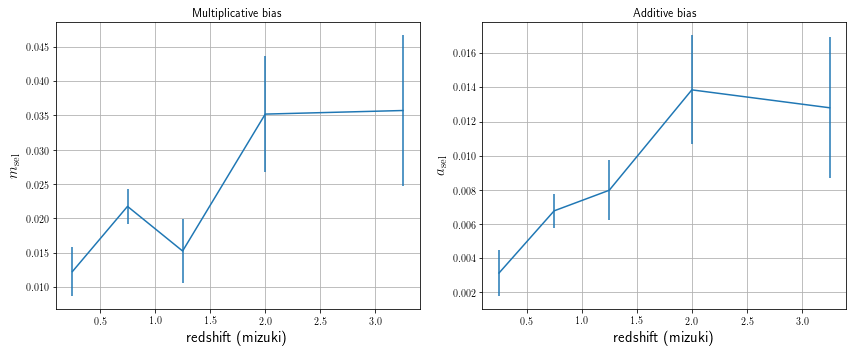

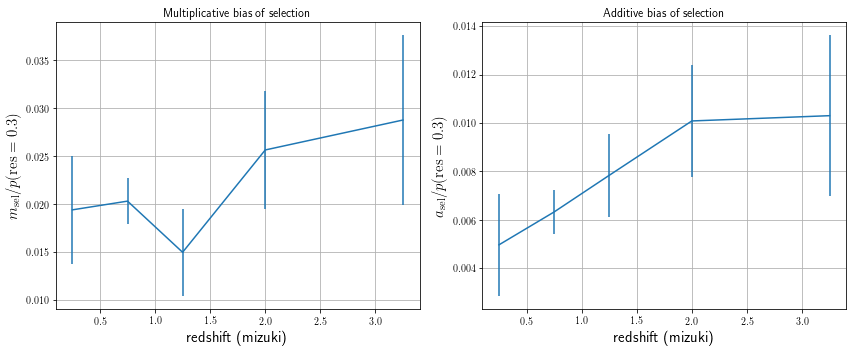

In [36]:
grid1,m_res1,sigm1,a_res1,siga1,pedge1=makePlotSelBias('res','mizuki_Z',dataU2,doPlot=True)

/work/xiangchong.li/lsstsw/miniconda/envs/lsst-scipipe/lib/python3.7/site-packages/ipykernel_launcher.py:84: RuntimeWarning: invalid value encountered in greater_equal
/work/xiangchong.li/lsstsw/miniconda/envs/lsst-scipipe/lib/python3.7/site-packages/ipykernel_launcher.py:84: RuntimeWarning: invalid value encountered in less


[0.17819441 0.11246926 0.21073235 0.32186505 0.69901706]


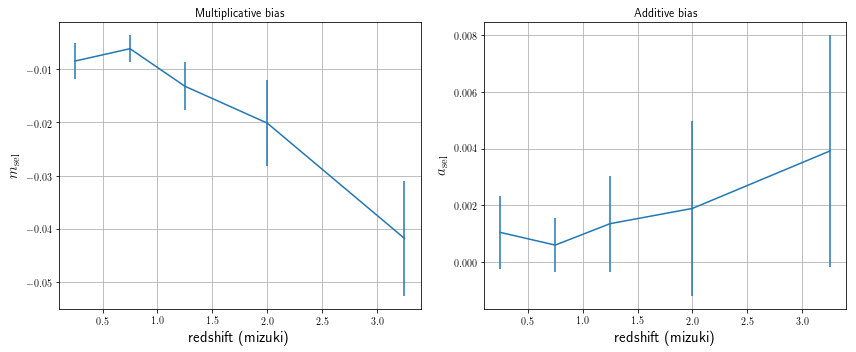

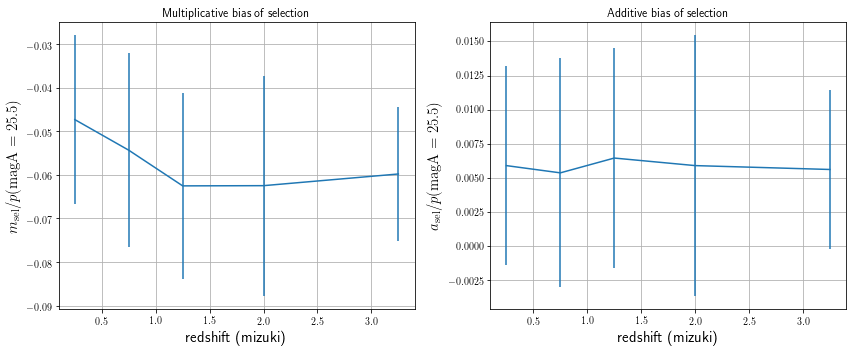

In [37]:
grid2,m_res2,sigm2,a_res2,siga2,pedge2=makePlotSelBias('magA10','mizuki_Z',dataU2,doPlot=True)

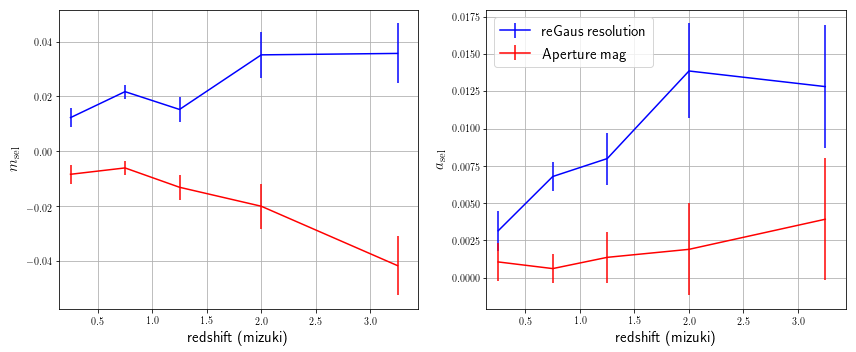

In [46]:
label1='reGaus resolution'
label2='Aperture mag'

fig = plt.figure(figsize=(12,5))

ax1 = fig.add_subplot(1,2,1)
ax1.errorbar(grid1,m_res1,sigm1,color='blue',label=label1)
ax1.errorbar(grid2, m_res2,sigm2,color='red',label=label2)
ax1.set_xlabel('redshift (mizuki)',fontsize=15)
ax1.set_ylabel(r'$m_{\rm{sel}}$',fontsize=15)

left, right = ax1.get_xlim()
dd=np.abs((right-left)/80.)
ax1.set_xlim(left+dd,right+dd)
plt.grid()


ax1 = fig.add_subplot(1,2,2)
ax1.errorbar(grid1, a_res1,siga1,color='blue',label=label1)
ax1.errorbar(grid2, a_res2,siga2,color='red',label=label2)
ax1.set_xlabel('redshift (mizuki)',fontsize=15)
ax1.set_ylabel(r'$a_{\rm{sel}}$',fontsize=15)

left, right = ax1.get_xlim()
dd=np.abs((right-left)/80.)
ax1.set_xlim(left+dd,right+dd)
plt.grid()
plt.legend(fontsize=15,loc='upper left')

plt.tight_layout()
plt.savefig(os.path.join(pltDir,'selBias_redshift.eps'))

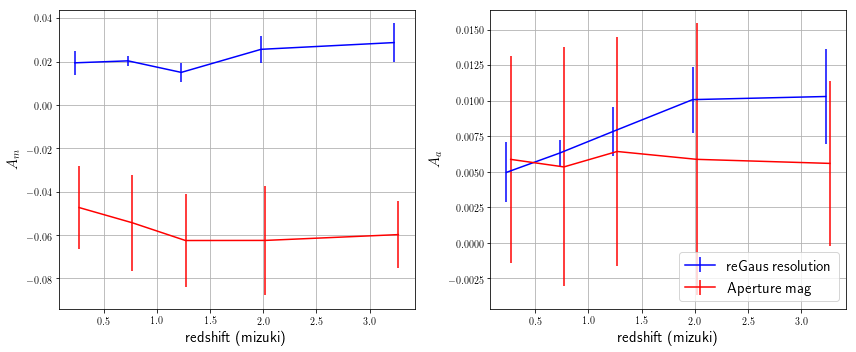

In [49]:
label1='reGaus resolution'
label2='Aperture mag'

fig = plt.figure(figsize=(12,5))

ax1 = fig.add_subplot(1,2,1)
ax1.errorbar(grid1-0.02,m_res1/pedge1,sigm1/pedge1,color='blue',label=label1)
ax1.errorbar(grid2+0.02, m_res2/pedge2,sigm2/pedge2,color='red',label=label2)
ax1.set_xlabel('redshift (mizuki)',fontsize=15)
ax1.set_ylabel(r'$A_{m}$',fontsize=15)

plt.grid()


ax1 = fig.add_subplot(1,2,2)
ax1.errorbar(grid1-0.02, a_res1/pedge1,siga1/pedge1,color='blue',label=label1)
ax1.errorbar(grid2+0.02, a_res2/pedge2,siga2/pedge2,color='red',label=label2)
ax1.set_xlabel('redshift (mizuki)',fontsize=15)
ax1.set_ylabel(r'$A_{a}$',fontsize=15)

plt.grid()
plt.legend(fontsize=15,loc='lower right')

plt.tight_layout()
plt.savefig(os.path.join(pltDir,'selBias_ratio_redshift.eps'))